# 06 - Futures volatility term structure, $\kappa_{\mathbb Q}$ and the Schwartz-Smith model

Notebook 02 calibrated $\kappa$ on the mean reversion of front-month *price levels*, a historical-measure estimate,
and flagged that it equals the pricing-measure $\kappa$ only if the market price of risk is constant. Volatility
does not change under an equivalent change of measure, so the **term structure of futures volatilities** identifies
the risk-neutral parameters directly.

**Data.** Yahoo Finance serves the individual NYMEX TTF monthly futures that are listed at download time
(`TTFZ26.NYM`, `TTFF27.NYM`, `TTFG27.NYM`), each with daily closes since January 2023. Over that history each
contract was observed at every time to delivery from about 4 years down to a few weeks.

**Estimator** (`gasstorage.models.vol_term_structure`). For one contract, maturity and calendar time move together,
and volatility regimes differ a lot between 2023 and 2025. Each contract's volatility is therefore measured relative
to the front month over the **same days**, $R(\tau) = \hat\sigma_{\text{contract}}(\tau)/\hat\sigma_{\text{front}}$, in
two-month bins of time to delivery, together with the correlation of daily returns.

* One factor: $R(\tau) = e^{-\kappa(\tau-\tau_f)}$ and correlation 1.
* Schwartz-Smith: $\sigma_F(\tau)^2 = \sigma_\chi^2e^{-2\kappa\tau} + \sigma_\xi^2 + 2\rho\sigma_\chi\sigma_\xi e^{-\kappa\tau}$,
  and correlations below 1 that fall with maturity.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.data.forward_curve import load_settlements
from gasstorage.data.ttf import contract_ticker, get_contract_history, get_ttf_history
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.models.two_factor import TwoFactorModel
from gasstorage.models.vol_term_structure import (
    TAU_FRONT,
    fit_one_factor_kappa,
    fit_two_factor,
    two_factor_correlation,
    two_factor_forward_vol,
    vol_ratio_table,
)
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.dp import solve_dp
from gasstorage.storage.lsmc import lsmc_value
from gasstorage.storage.rolling_intrinsic import rolling_intrinsic

plotting.apply_style()
months = [pd.Period(m, "M") for m in ("2026-12", "2027-01", "2027-02")]
contracts = get_contract_history(months)  # cached in data/raw/ttf_contracts.csv
front = get_ttf_history()
print({str(m): contract_ticker(m) for m in months})
contracts.describe().round(2)

{'2026-12': 'TTFZ26.NYM', '2027-01': 'TTFF27.NYM', '2027-02': 'TTFG27.NYM'}


,2026-12,2027-01,2027-02
count,975.00,975.00,974.00
mean,38.52,38.55,38.08
std,13.00,12.87,12.68
min,26.58,26.76,26.69
25%,32.30,32.42,32.12
50%,34.35,34.37,33.91
75%,37.23,37.24,36.83
max,103.94,103.52,102.82


**Check against EEX.** Yahoo closes of 2026-11-17 against the EEX settlements used for the forward curve:

In [2]:
eex = load_settlements("data/raw/eex_ttf_futures_settlements_2026-11-17.csv").set_index("contract")
day = pd.Timestamp("2026-11-17")
pd.DataFrame(
    {
        "Yahoo NYMEX close": [contracts.loc[day, "2027-01"], contracts.loc[day, "2027-02"]],
        "EEX settlement": [
            eex.loc["Jan-27", "settlement_eur_mwh"],
            eex.loc["Feb-27", "settlement_eur_mwh"],
        ],
    },
    index=["Jan-27", "Feb-27"],
).round(3)

,Yahoo NYMEX close,EEX settlement
Jan-27,85.301,85.350
Feb-27,84.860,84.899


## 1. Volatility ratio and correlation by time to delivery

In [3]:
starts = {c: pd.Period(c, "M").start_time for c in contracts.columns}
table = vol_ratio_table(contracts, starts, front)
cfg = load_config("configs/storage_default.yaml")
sigma_front = cfg.model.sigma  # front-month volatility of the reference calibration
fit1 = fit_one_factor_kappa(table)
fit2 = fit_two_factor(table, front_vol=sigma_front)
print(f"one factor : kappa_Q = {fit1.kappa:.3f} +/- {fit1.se_kappa:.3f} per year")
print(f"             half-life {fit1.half_life_years:.2f} years")
print(f"historical : kappa_P = {cfg.model.kappa:.3f} per year (notebook 02)")
print(f"two factors: kappa = {fit2.kappa:.3f}, sigma_chi = {fit2.sigma_chi:.3f},")
print(f"             sigma_xi = {fit2.sigma_xi:.3f}, rho = {fit2.rho:.2f}")
print("            standard errors:", {k: round(v, 3) for k, v in fit2.se.items()})
table.round(3)

one factor : kappa_Q = 0.326 +/- 0.021 per year (half-life 2.13 y)
historical : kappa_P = 4.784 per year (notebook 02)
two factors: kappa = 0.459, sigma_chi = 0.742, sigma_xi = 0.272, rho = -0.31
            standard errors: {'kappa': 0.121, 'sigma_xi/sigma_chi': 0.03, 'rho': 0.38}


,tau,ratio,se,n,corr,vol_contract,vol_front
0,0.111,1.006,0.005,47,0.999,0.649,0.645
1,0.254,0.994,0.006,118,0.998,0.557,0.560
2,0.416,0.965,0.010,128,0.993,0.546,0.566
3,0.584,0.920,0.013,124,0.988,0.567,0.616
4,0.750,0.869,0.027,126,0.938,0.937,1.079
5,0.917,0.632,0.029,125,0.860,0.661,1.046
6,1.085,0.603,0.027,122,0.870,0.235,0.390
7,1.249,0.628,0.020,128,0.931,0.168,0.267
8,1.416,0.556,0.019,127,0.923,0.199,0.358
9,1.584,0.532,0.019,124,0.919,0.251,0.472


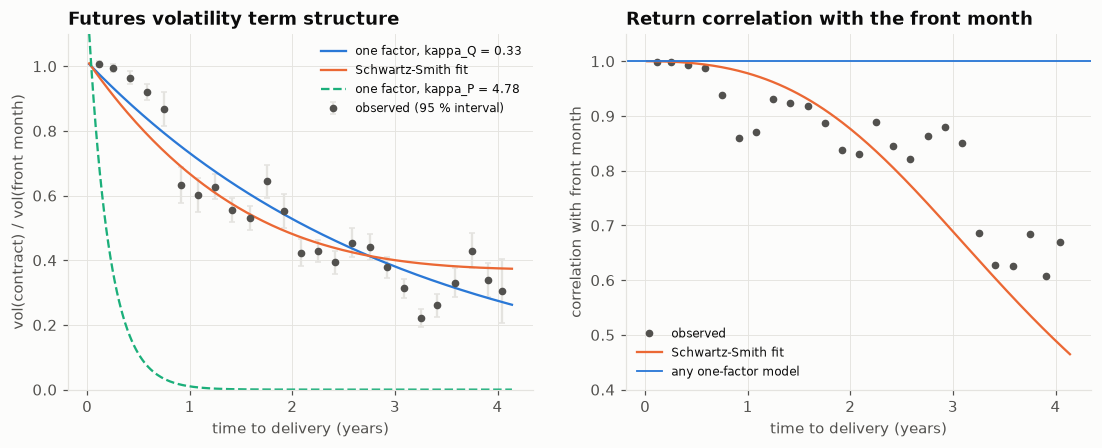

In [4]:
tau_grid = np.linspace(0.02, table["tau"].max() + 0.1, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.errorbar(
    table["tau"],
    table["ratio"],
    yerr=1.96 * table["se"],
    fmt="o",
    ms=4,
    color=plotting.TEXT_SECONDARY,
    ecolor=plotting.GRID,
    capsize=2,
    label="observed (95 % interval)",
)
ax.plot(
    tau_grid,
    np.exp(-fit1.kappa * (tau_grid - TAU_FRONT)),
    color=plotting.SERIES[0],
    label=f"one factor, kappa_Q = {fit1.kappa:.2f}",
)
r2 = (
    two_factor_forward_vol(tau_grid, fit2.kappa, fit2.sigma_chi, fit2.sigma_xi, fit2.rho)
    / sigma_front
)
ax.plot(tau_grid, r2, color=plotting.SERIES[1], label="Schwartz-Smith fit")
ax.plot(
    tau_grid,
    np.exp(-cfg.model.kappa * (tau_grid - TAU_FRONT)),
    color=plotting.SERIES[2],
    ls="--",
    label=f"one factor, kappa_P = {cfg.model.kappa:.2f}",
)
ax.set_xlabel("time to delivery (years)")
ax.set_ylabel("vol(contract) / vol(front month)")
ax.set_title("Futures volatility term structure")
ax.set_ylim(0, 1.1)
ax.legend(loc="upper right", fontsize=8)
ax = axes[1]
ax.plot(table["tau"], table["corr"], "o", ms=4, color=plotting.TEXT_SECONDARY, label="observed")
ax.plot(
    tau_grid,
    two_factor_correlation(
        tau_grid, TAU_FRONT, fit2.kappa, fit2.sigma_chi, fit2.sigma_xi, fit2.rho
    ),
    color=plotting.SERIES[1],
    label="Schwartz-Smith fit",
)
ax.axhline(1.0, color=plotting.SERIES[0], lw=1.2, label="any one-factor model")
ax.set_xlabel("time to delivery (years)")
ax.set_ylabel("correlation with front month")
ax.set_title("Return correlation with the front month")
ax.set_ylim(0.4, 1.05)
ax.legend(loc="lower left", fontsize=8)
plotting.save_figure(fig, "06_vol_term_structure")
fig

**Reading.**

* The relative volatility of a contract decays smoothly with time to delivery, to about 0.3 four years out.
  The one-factor fit gives a risk-neutral mean reversion $\kappa_{\mathbb Q} \approx 0.33$ per year (half-life about
  two years), **more than ten times slower** than the historical $\kappa_{\mathbb P} = 4.8$ of notebook 02. With
  $\kappa = 4.8$ the model would make a one-year forward almost static ($R \approx 0.01$), which the market
  clearly contradicts.
* Correlations with the front month fall from 1 to about 0.6 at long maturities, which no one-factor model can
  produce. The Schwartz-Smith fit uses both curves and finds a long-term factor with volatility of about 0.27.
* Why $\kappa_{\mathbb P} \gg \kappa_{\mathbb Q}$: a mean-reverting **state-dependent risk premium**
  ($\kappa_{\mathbb Q} = \kappa_{\mathbb P} + \sigma\lambda_1$ with $\lambda_1 < 0$), the small-sample upward bias of
  $\hat\kappa_{\mathbb P}$ (Dickey-Fuller $-3.0$), and the fact that the front month rolls every month so its level
  mixes delivery months. Far contracts also trade thinly, which lowers measured correlations.

Caveats: three contracts only, 2023-2026; overlapping contracts make the bins dependent (standard errors are
scaled by the residual dispersion); $\rho$ is weakly identified.

## 2. Storage value under historical and risk-neutral parameters

Same contract, weekly decisions, 101 volume levels, 10,000 + 10,000 LSMC paths (seeds 12345 / 67890), rolling
intrinsic on 2,000 paths. Three parameter sets:

1. **one factor, $\mathbb P$** (reference of notebooks 03-05): $\kappa = 4.78$, $\sigma = 0.694$;
2. **one factor, $\mathbb Q$**: $\kappa = \kappa_{\mathbb Q}$ from the volatility term structure, same $\sigma$;
3. **Schwartz-Smith, $\mathbb Q$**: the two-factor fit above (front-month volatility matched to 0.694).

In [5]:
models = {
    "1F, P (reference)": OneFactorModel(cfg.model.kappa, cfg.model.sigma),
    "1F, Q (vol term structure)": OneFactorModel(fit1.kappa, cfg.model.sigma),
    "2F Schwartz-Smith, Q": TwoFactorModel(fit2.kappa, fit2.sigma_chi, fit2.sigma_xi, fit2.rho),
}
cases = {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}
rows, fans = [], {}
for case, path in cases.items():
    inp = build_inputs(load_config(path), "weekly")
    intr = solve_dp(inp.contract, inp.prices, inp.days, inp.discount, n_levels=101).value
    for name, model in models.items():
        t0 = time.perf_counter()
        res = lsmc_value(
            inp,
            model,
            10_000,
            10_000,
            np.random.default_rng(12345),
            np.random.default_rng(67890),
            n_levels=101,
        )
        el = time.perf_counter() - t0
        ri = rolling_intrinsic(inp, model, 2000, np.random.default_rng(2027), n_levels=101)
        fans[(case, name)] = (inp, res)
        rows.append(
            {
                "case": case,
                "model": name,
                "intrinsic": intr / 1e6,
                "rolling intrinsic": ri.value / 1e6,
                "RI SE": ri.se / 1e6,
                "LSMC": res.value / 1e6,
                "LSMC SE": res.se / 1e6,
                "extrinsic (LSMC - intrinsic)": (res.value - intr) / 1e6,
                "LSMC time (s)": el,
            }
        )
values = pd.DataFrame(rows).set_index(["case", "model"])
print("MEUR, discounted to 2026-11-17")
values.round(3)

MEUR, discounted to 2026-11-17


intrinsic  rolling intrinsic  \
case                 model                                                      
market (EEX)         1F, P (reference)               0.000              3.528   
                     1F, Q (vol term structure)      0.000              0.040   
                     2F Schwartz-Smith, Q            0.000              0.292   
contango (SYNTHETIC) 1F, P (reference)               6.434              7.620   
                     1F, Q (vol term structure)      6.434              6.970   
                     2F Schwartz-Smith, Q            6.434              6.709   

                                                 RI SE   LSMC  LSMC SE  \
case                 model                                               
market (EEX)         1F, P (reference)           0.118  4.895    0.058   
                     1F, Q (vol term structure)  0.032 -0.128    0.025   
                     2F Schwartz-Smith, Q        0.093  0.081    0.049   
contango (SYNTHETIC) 1F, P (reference)           0.128  7.980    0.055   
                     1F, Q (vol term structure)  0.328  6.546    0.148   
                     2F Schwartz-Smith, Q        0.305  6.514    0.139   

                                                 extrinsic (LSMC - intrinsic)  \
case                 model                                                      
market (EEX)         1F, P (reference)                                  4.895   
                     1F, Q (vol term structure)                        -0.128   
                     2F Schwartz-Smith, Q                               0.081   
contango (SYNTHETIC) 1F, P (reference)                                  1.546   
                     1F, Q (vol term structure)                         0.112   
                     2F Schwartz-Smith, Q                               0.079   

                                                 LSMC time (s)  
case                 model                                      
market (EEX)         1F, P (reference)                  23.549  
                     1F, Q (vol term structure)         24.231  
                     2F Schwartz-Smith, Q               27.380  
contango (SYNTHETIC) 1F, P (reference)                  23.832  
                     1F, Q (vol term structure)         23.581  
                     2F Schwartz-Smith, Q               23.449

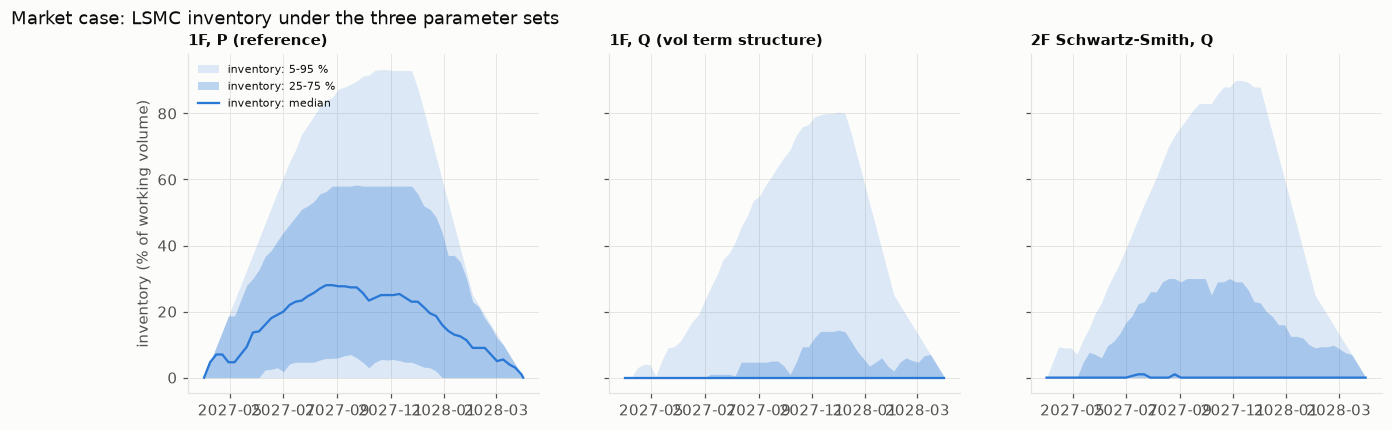

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, models, strict=True):
    inp, res = fans[("market (EEX)", name)]
    dates = inp.dates.append(
        pd.DatetimeIndex([inp.dates[-1] + pd.Timedelta(days=int(inp.days[-1]))])
    )
    plotting.fan_chart(
        ax, dates, 100 * res.inventory / inp.contract.working_volume, label="inventory"
    )
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("inventory (% of working volume)")
axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("Market case: LSMC inventory under the three parameter sets", x=0.01, ha="left")
plotting.save_figure(fig, "06_inventory_by_model")
fig

## 3. Findings

**Data and parameters.** Yahoo's NYMEX TTF contracts match the EEX settlements used for the curve within
0.05 EUR/MWh. The futures volatility term structure gives $\kappa_{\mathbb Q} = 0.33 \pm 0.02$ per year in the
one-factor model (half-life 2.1 years) against $\kappa_{\mathbb P} = 4.78$ from front-month levels. Adding the
correlations identifies a Schwartz-Smith model with $\kappa = 0.46 \pm 0.12$, $\sigma_\chi = 0.74$,
$\sigma_\xi = 0.27$ ($\sigma_\xi/\sigma_\chi = 0.37 \pm 0.03$) and a weakly identified $\rho = -0.31 \pm 0.38$; it
reproduces the decay of relative volatility well and the fall of correlations only roughly (observed correlations
plateau around 0.85 between one and three years before dropping).

**The storage value depends on which mean reversion is priced.**

| MEUR | 1F, $\mathbb P$ ($\kappa$ 4.78) | 1F, $\mathbb Q$ ($\kappa$ 0.33) | 2F Schwartz-Smith, $\mathbb Q$ |
|---|---|---|---|
| market case, LSMC | 4.90 (0.06) | -0.13 (0.03) | 0.08 (0.05) |
| market case, rolling intrinsic | 3.53 (0.12) | 0.04 (0.03) | 0.29 (0.09) |
| contango case, LSMC | 7.98 (0.06) | 6.55 (0.15) | 6.51 (0.14) |
| contango case, intrinsic | 6.43 | 6.43 | 6.43 |

* Under the historical dynamics the front month reverts with a half-life of 53 days: a dip below the curve is likely
  to be recovered within weeks, which the storage monetises (4.9 MEUR on the backwardated market curve).
* Under the risk-neutral dynamics implied by futures volatilities, deviations persist for years. Buying a dip is no
  longer a good bet within the storage year, and the extrinsic value almost vanishes: about 0.1-0.3 MEUR in the market
  case, 0.1 MEUR on top of the intrinsic value in the contango case.
* The LSMC value under one-factor $\mathbb Q$ is slightly **negative**: the estimated policy trades on regression
  noise and pays injection / withdrawal costs, so it does worse than doing nothing (value 0, always feasible). It is a
  valid but loose lower bound; notebook 07 brackets the optimum with a dual upper bound.
* Under the two-factor model the rolling intrinsic strategy (0.29 MEUR) beats the LSMC policy (0.08 MEUR): with a
  persistent long-term factor, re-optimising against the forward curve is close to optimal and the cubic basis in
  two factors is a weak approximation of the continuation value.

**Which number to believe.** A trading desk prices what it can hedge: forward-curve optionality should be valued with
risk-neutral (market-implied) dynamics, which here say the 2027/28 storage is worth little beyond its intrinsic value.
The historical mean reversion of the front month is a statistical view, not a hedgeable one; part of it may be real
(day-ahead spot shocks revert within days and are invisible in monthly futures), part reflects a risk premium and
estimation error. A model with a separate fast spot factor, calibrated to day-ahead prices, would be needed to value
that intra-month flexibility properly.